# Laboratorio 8: Monte Carlo y cadenas de Markov (MCMC)

**Andrés Felipe Serrano Barrios**

Física Computacional I (0302151), grupo 001

Instituto de Física, Universidad de Antioquia

Semestre 2026-2, profesor Andrés Felipe Rivera Romero

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": False})

random.seed(2026)
np.random.seed(2026)

---

# 1. Integración Monte Carlo

La rutina `monte_carlo_integration` de la [sesión de integración Monte Carlo](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/MC/1_Monte_Carlo_MC_integration.ipynb) estima

$$\int_a^b f(x)\,dx\approx(b-a)\,\frac{1}{N}\sum_{i=1}^{N}f(x_i),$$

con $N$ puntos $x_i$ uniformes en $[a,b]$. Las semillas de la primera celda fijan los números aleatorios, de modo
que los valores del texto se repiten al volver a correr el cuaderno.

**Paso 1. Integral simple.** Con la primitiva $\int x^{1/2}\,dx=\dfrac{x^{3/2}}{3/2}=\dfrac{2}{3}x^{3/2}$,

$$\int_0^4x^{1/2}\,dx=\frac{2}{3}\left(4^{3/2}-0\right)=\frac{2}{3}\cdot8=\frac{16}{3}\approx5{,}33333.$$

**Paso 2. Integral doble.** El integrando es un producto de una función de $x$ y una de $y$, y los límites son
constantes, así que la integral doble es el producto de dos integrales simples:

$$\int_0^2\int_0^1xy^2\,dy\,dx=\left(\int_0^2x\,dx\right)\left(\int_0^1y^2\,dy\right)
=\left[\frac{x^2}{2}\right]_0^2\left[\frac{y^3}{3}\right]_0^1=2\cdot\frac{1}{3}=\frac{2}{3}\approx0{,}66667.$$

**Paso 3. Monte Carlo en dos variables.** El promedio de $f$ sobre el rectángulo $R=[a,b]\times[c,d]$ es

$$\langle f\rangle_R=\frac{1}{(b-a)(d-c)}\iint_Rf(x,y)\,dA,$$

así que

$$\iint_Rf(x,y)\,dA=(b-a)(d-c)\,\langle f\rangle_R\approx(b-a)(d-c)\,\frac{1}{N}\sum_{i=1}^{N}f(x_i,y_i),$$

con $N$ puntos $(x_i,y_i)$ uniformes en $R$. La rutina `monte_carlo_integration_2D` tiene la misma estructura que
la de clase: cada punto lleva una segunda coordenada aleatoria y el promedio se multiplica por el área del
rectángulo en lugar de la longitud del intervalo.

In [2]:
def monte_carlo_integration(func, a, b, num_samples=1000):
    integral_sum = 0
    for _ in range(num_samples):
        x = random.uniform(a, b)
        integral_sum += func(x)
    integral_approx = (b - a) * (integral_sum / num_samples)
    return integral_approx


def monte_carlo_integration_2D(func, a, b, c, d, num_samples=1000):
    integral_sum = 0
    for _ in range(num_samples):
        x = random.uniform(a, b)
        y = random.uniform(c, d)
        integral_sum += func(x, y)
    integral_approx = (b - a) * (d - c) * (integral_sum / num_samples)
    return integral_approx

In [3]:
def f(x):
    return x**0.5


def f2(x, y):
    return x*y**2


exacta_1 = 16/3
exacta_2 = 2/3

print(f"{'muestras':>10} {'simple':>10} {'error':>9} {'doble':>10} {'error':>9}")
for num_samples in [1000, 10000, 100000, 1000000]:
    simple = monte_carlo_integration(f, 0, 4, num_samples)
    doble = monte_carlo_integration_2D(f2, 0, 2, 0, 1, num_samples)
    print(f"{num_samples:>10} {simple:>10.5f} {abs(simple - exacta_1):>9.1e} {doble:>10.5f} {abs(doble - exacta_2):>9.1e}")

print(f"\nValores analíticos: {exacta_1:.5f} y {exacta_2:.5f}")

  muestras     simple     error      doble     error
      1000    5.33596   2.6e-03    0.61576   5.1e-02
     10000    5.28694   4.6e-02    0.66245   4.2e-03
    100000    5.32778   5.6e-03    0.66352   3.1e-03


   1000000    5.33280   5.3e-04    0.66571   9.6e-04

Valores analíticos: 5.33333 y 0.66667


Los dos valores se acercan a los analíticos al aumentar el número de muestras. Con un millón de puntos el error es de
$5\times10^{-4}$ en la integral simple (0,01 %) y de $1\times10^{-3}$ en la doble (0,14 %). El error no baja en todas las
filas porque cada estimación es aleatoria, como se ve con 10 000 muestras en la integral simple.

---

# 2. Modelo de Ising 2D

## Modelo de Ising en 1D, 2D y 3D

En el [modelo de Ising](https://en.wikipedia.org/wiki/Ising_model) cada nodo $i$ de una red tiene un espín
$s_i=\pm1$, y la energía de una configuración es

$$E=-J\sum_{\langle ij\rangle}s_is_j-\mu H\sum_is_i,$$

donde la primera suma recorre los pares de vecinos más cercanos, $J$ es la energía de acople entre vecinos y
$\mu H$ la energía de un espín en el campo externo. Con $J>0$ los vecinos tienden a alinearse, que es el caso
ferromagnético. El modelo lo propuso W. Lenz en 1920 y lo estudió su estudiante E. Ising.

- **1D.** Ising resolvió la cadena en 1925 ([Ising, 1925](https://doi.org/10.1007/BF02980577)). Sin campo, la
  magnetización espontánea es nula a cualquier temperatura $T>0$: en una dimensión no hay transición de fase.
- **2D.** R. Peierls mostró en 1936 que en la red cuadrada sí hay orden a baja temperatura
  ([Peierls, 1936](https://doi.org/10.1017/S0305004100019174)). L. Onsager obtuvo en 1944 la solución exacta sin
  campo ([Onsager, 1944](https://doi.org/10.1103/PhysRev.65.117)), con la temperatura crítica
  $k_BT_c=2J/\ln(1+\sqrt2)\approx2{,}269\,J$, y C. N. Yang calculó en 1952 la magnetización espontánea,
  $m=\left[1-\sinh^{-4}(2J/k_BT)\right]^{1/8}$ para $T<T_c$ ([Yang, 1952](https://doi.org/10.1103/PhysRev.85.808)).
- **3D.** No tiene solución exacta. La temperatura crítica de la red cúbica simple se conoce por simulaciones de
  Monte Carlo, $k_BT_c\approx4{,}5115\,J$ ([Ferrenberg, Xu y Landau, 2018](https://doi.org/10.1103/PhysRevE.97.043301)).

## Simulación de la red 2D

El enunciado describe átomos no interactuantes y pide además considerar la interacción con los primeros vecinos.
La misma rutina cubre los dos casos: con $J=0$ es el sistema no interactuante de la
[sesión de MCMC](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/MC/2_Monte_Carlo_Marckov_chain_MCMC.ipynb), que tiene solución exacta, y con $J>0$ se agregan los vecinos.

**Paso 1. Energía de la red.** Cada nodo $(i,j)$ de una red cuadrada de $L\times L$ átomos tiene cuatro vecinos,
$(i\pm1,j)$ y $(i,j\pm1)$. Con fronteras periódicas el índice $L$ equivale a $0$ y el $-1$ a $L-1$, de modo que los
nodos del borde también tienen cuatro vecinos. El momento magnético de cada átomo es el magnetón de Bohr,
$\mu_0=\mu_B=9{,}274\times10^{-24}$ J/T (espín $1/2$ con $g\approx2$), y el campo del enunciado, en teslas, se
escribe $B$:

$$E=-J\sum_{\langle ij\rangle}s_is_j-\mu_BB\sum_is_i.$$

**Paso 2. Cambio de energía al invertir un espín.** Al invertir el espín $s$ del nodo $(i,j)$ solo cambian los
cuatro enlaces con sus vecinos y su término de campo. Con $S_v=s_{i+1,j}+s_{i-1,j}+s_{i,j+1}+s_{i,j-1}$,

$$E_{ij}(s)=-J\,s\,S_v-\mu_BB\,s,$$

$$\Delta E=E_{ij}(-s)-E_{ij}(s)=\left(J\,s\,S_v+\mu_BB\,s\right)-\left(-J\,s\,S_v-\mu_BB\,s\right)
=2\,s\left(J\,S_v+\mu_BB\right).$$

Con $J=0$ queda $\Delta E=2\,\mu_BB\,s$, el de la sesión.

**Paso 3. Solución sin vecinos.** Con $J=0$ cada átomo es independiente. Con $x=\dfrac{\mu_BB}{k_BT}$, la
distribución canónica de un átomo es

$$P(s)=\frac{e^{\mu_BBs/k_BT}}{Z_1},\qquad Z_1=\sum_{s=\pm1}e^{\mu_BBs/k_BT}=e^{x}+e^{-x}=2\cosh x,$$

el espín medio es

$$\langle s\rangle=\sum_{s=\pm1}s\,P(s)=\frac{(+1)\,e^{x}+(-1)\,e^{-x}}{e^{x}+e^{-x}}=\tanh x,$$

y cada átomo aporta $\mu_B\langle s\rangle$:

$$M=N\mu_B\tanh\left(\frac{\mu_BB}{k_BT}\right).$$

$M$ depende solo de $B/T$, y satura en $\pm N\mu_B$ cuando $|B|\gg k_BT/\mu_B$, que vale 7,44, 14,89 y 22,33 T en 5,
10 y 15 K. La comparación de la sesión usa $\tanh(H/T)$; con el campo en teslas el argumento lleva además el factor
$\mu_B/k_B=0{,}6717$ K/T.

**Paso 4. Solución con vecinos y elección de $J$.** Con campo, la red 2D con vecinos no tiene solución exacta. Sin
campo, Onsager y Yang dan la temperatura crítica y la magnetización espontánea,

$$k_BT_c=\frac{2J}{\ln(1+\sqrt2)},\qquad
\frac{M}{N\mu_B}=\left[1-\sinh^{-4}\left(\frac{2J}{k_BT}\right)\right]^{1/8}\ \ \text{si}\ T<T_c,\qquad
M=0\ \ \text{si}\ T\geq T_c.$$

El enunciado no da $J$. Se elige para que $T_c$ coincida con la temperatura intermedia, 10 K:

$$\frac{J}{k_B}=\frac{T_c\ln(1+\sqrt2)}{2}=\frac{(10\ \text{K})(0{,}8814)}{2}=4{,}407\ \text{K},\qquad
J=6{,}084\times10^{-23}\ \text{J}.$$

Así 5 K queda por debajo de $T_c$, 10 K en $T_c$ y 15 K por encima. En 5 K, $T=T_c/2$ y
$2J/k_BT=2\ln(1+\sqrt2)$. Con $(1+\sqrt2)^{-1}=\sqrt2-1$,

$$\sinh\left(2\ln(1+\sqrt2)\right)=\frac{(1+\sqrt2)^2-(\sqrt2-1)^2}{2}=\frac{(3+2\sqrt2)-(3-2\sqrt2)}{2}=2\sqrt2,$$

$$\frac{M}{N\mu_B}=\left[1-\frac{1}{(2\sqrt2)^4}\right]^{1/8}=\left(\frac{63}{64}\right)^{1/8}=0{,}9980.$$

Por debajo de $T_c$ la red conserva el signo de su magnetización cuando el campo se apaga, así que $M(B)$ depende
del recorrido del campo. Por eso, con $J>0$ el campo se recorre de $-30$ a $30$ T y de vuelta.

**Paso 5. Metropolis.** El algoritmo de la sesión acepta la inversión si $\Delta E\leq0$, y si $\Delta E>0$ la
acepta cuando un número aleatorio $r$ en $[0,1]$ es menor que $e^{-\Delta E/k_BT}$. Entre dos configuraciones $x$ y
$x'$ con $E(x')>E(x)$, el paso $x\to x'$ se acepta con probabilidad $e^{-\Delta E/k_BT}$ y el paso $x'\to x$
siempre. En equilibrio los dos flujos se compensan:

$$P(x)\,e^{-\Delta E/k_BT}=P(x')\cdot1\quad\Rightarrow\quad
\frac{P(x')}{P(x)}=e^{-[E(x')-E(x)]/k_BT}=\frac{e^{-E(x')/k_BT}}{e^{-E(x)/k_BT}},$$

que es la razón de la distribución canónica, con o sin vecinos.

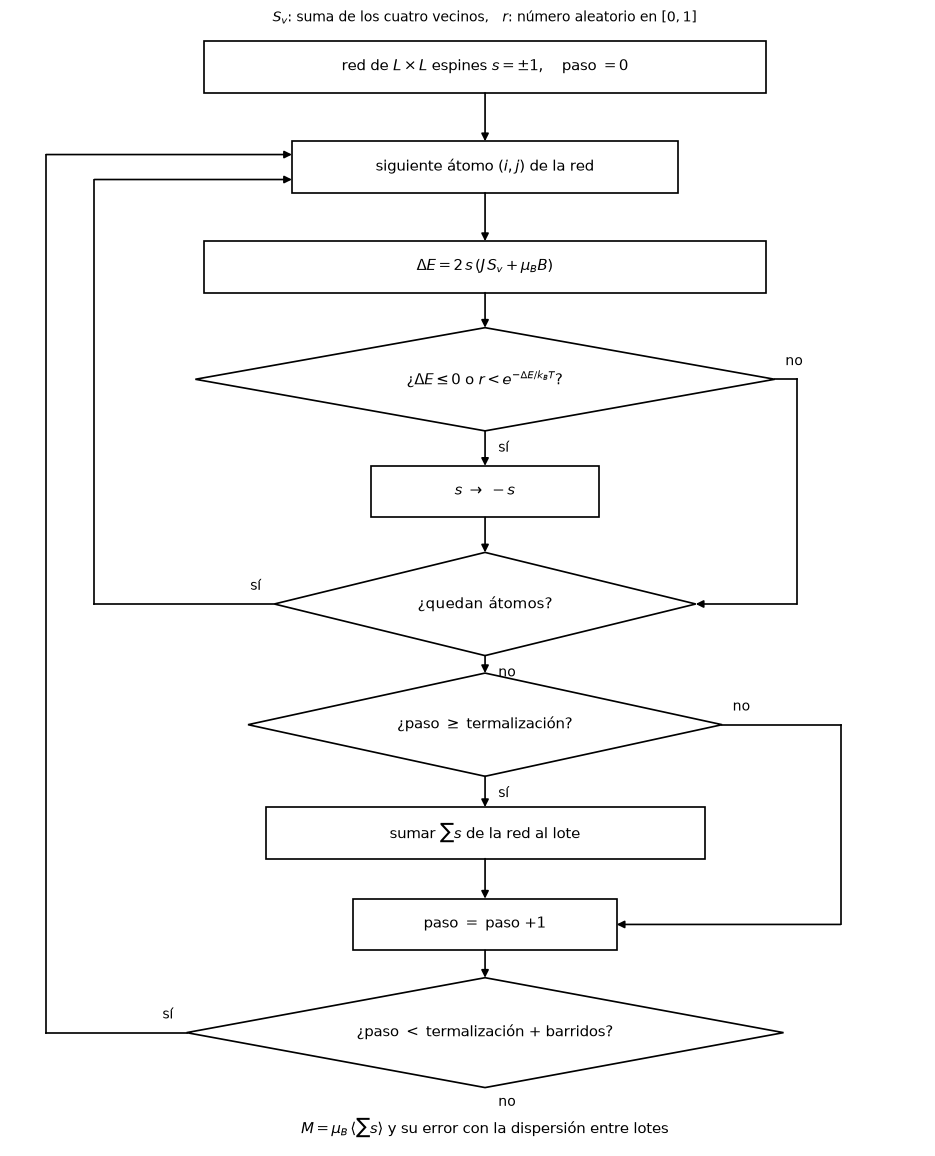

Cambios respecto al código de Ising de la sesión:

- La energía lleva el término de los vecinos (paso 2), con fronteras periódicas. Con $J=0$ coincide con la de la
  sesión.
- Las constantes van por separado, $\mu_B$ y $k_B$, en lugar de $C=\mu_B/k_B$, porque $J$ no se expresa en teslas.
- Antes de promediar se descartan los barridos de termalización, y la suma de los espines se acumula una vez por
  barrido.
- Los barridos de medida se agrupan en lotes, y la dispersión entre los promedios de los lotes da el error.
- La red es una lista de Python, y el número aleatorio y la exponencial salen de `random` y `math`, que son más
  rápidos que numpy para un valor suelto dentro del ciclo.

In [4]:
mu_B = 9.2740100657e-24
k_B = 1.380649e-23


def metropolis_ising(red, T, B, J, barridos, termalizacion, lotes):
    L = len(red)
    suma = 0
    for i in range(L):
        for j in range(L):
            suma = suma + red[i][j]

    por_lote = barridos//lotes
    promedios = []
    acumulado = 0
    for paso in range(termalizacion + barridos):
        for i in range(L):
            for j in range(L):
                s = red[i][j]
                vecinos = red[(i + 1) % L][j] + red[(i - 1) % L][j] + red[i][(j + 1) % L] + red[i][(j - 1) % L]
                energia = -J*s*vecinos - mu_B*B*s
                s_nuevo = -s
                energia_nueva = -J*s_nuevo*vecinos - mu_B*B*s_nuevo
                delta_E = energia_nueva - energia
                if delta_E <= 0:
                    red[i][j] = s_nuevo
                    suma = suma + 2*s_nuevo
                else:
                    b = math.exp(-delta_E/(k_B*T))
                    r = random.random()
                    if r < b:
                        red[i][j] = s_nuevo
                        suma = suma + 2*s_nuevo
        if paso >= termalizacion:
            acumulado = acumulado + suma
            if (paso + 1 - termalizacion) % por_lote == 0:
                promedios.append(acumulado/por_lote)
                acumulado = 0

    s_total = sum(promedios)/lotes
    varianza = 0.0
    for p in promedios:
        varianza = varianza + (p - s_total)**2
    varianza = varianza/(lotes - 1)
    return mu_B*s_total, mu_B*math.sqrt(varianza/lotes)

**Parámetros.** La red es de $L=10$, es decir $N=100$ átomos, y el campo va de $-30$ a $30$ T cada $0{,}5$ T, como en la
sesión. La red de cada temperatura arranca al azar y pasa de un campo al siguiente, también como en la sesión. En cada
campo se descartan 200 barridos de termalización y se promedian 2000, en 20 lotes de 100. Las 1089 simulaciones tardan
unos dos minutos.

In [5]:
L = 10
N = L*L
T_c = 10
J_vecinos = k_B*T_c*math.log(1 + math.sqrt(2))/2
temperaturas = [5, 10, 15]
campos_B = np.linspace(-30, 30, 121).tolist()

inicio = time.perf_counter()
filas = []
for J in [0.0, J_vecinos]:
    for T in temperaturas:
        red = np.random.choice([-1, 1], size=(L, L)).tolist()
        for B in campos_B:
            M, error = metropolis_ising(red, T, B, J, 2000, 200, 20)
            filas.append([J/k_B, T, "ida", B, M, error])
        if J > 0:
            for B in reversed(campos_B):
                M, error = metropolis_ising(red, T, B, J, 2000, 200, 20)
                filas.append([J/k_B, T, "vuelta", B, M, error])

datos = pd.DataFrame(filas, columns=["J/k_B", "T", "recorrido", "B", "M", "error"])
print(f"J/k_B = {J_vecinos/k_B:.3f} K,  J = {J_vecinos:.4e} J")
print(len(datos), "puntos en", round(time.perf_counter() - inicio, 1), "s")

J/k_B = 4.407 K,  J = 6.0843e-23 J
1089 puntos en 112.6 s


In [6]:
print(f"Sin vecinos: M = N mu_B tanh(mu_B B / k_B T) con N mu_B = {N*mu_B:.4e} J/T\n")
for T in temperaturas:
    tabla = datos[(datos["J/k_B"] == 0) & (datos["T"] == T)]
    cerca = 0
    mayor = 0.0
    for B, M, error in zip(tabla["B"], tabla["M"], tabla["error"]):
        teorica = N*mu_B*math.tanh(mu_B*B/(k_B*T))
        if abs(M - teorica) < 2*error:
            cerca = cerca + 1
        if abs(M - teorica) > mayor:
            mayor = abs(M - teorica)
    print(f"T = {T:2d} K:  {cerca} de {len(tabla)} puntos a menos de dos errores de la curva,"
          f"  diferencia máxima {100*mayor/(N*mu_B):.2f} % de N mu_B")

print(f"\nCon vecinos, J/k_B = {J_vecinos/k_B:.3f} K y T_c = {T_c} K: M/(N mu_B) con el campo apagado\n")
for T in temperaturas:
    if T < T_c:
        exacta = (1 - math.sinh(2*J_vecinos/(k_B*T))**-4)**(1/8)
    else:
        exacta = 0.0
    tabla = datos[(datos["J/k_B"] > 0) & (datos["T"] == T) & (datos["B"].abs() < 1e-9)]
    texto = ""
    for recorrido, M, error in zip(tabla["recorrido"], tabla["M"], tabla["error"]):
        texto = texto + f"  {recorrido}: {M/(N*mu_B):+.4f} ± {error/(N*mu_B):.4f}"
    ida = datos[(datos["J/k_B"] > 0) & (datos["T"] == T) & (datos["recorrido"] == "ida") & (datos["M"] > 0)]
    vuelta = datos[(datos["J/k_B"] > 0) & (datos["T"] == T) & (datos["recorrido"] == "vuelta") & (datos["M"] < 0)]
    print(f"T = {T:2d} K:  Onsager y Yang {exacta:.4f}  |{texto}")
    print(f"           cambio de signo: en la ida desde B = {ida['B'].min():+.1f} T,"
          f" en la vuelta desde B = {vuelta['B'].max():+.1f} T")

Sin vecinos: M = N mu_B tanh(mu_B B / k_B T) con N mu_B = 9.2740e-22 J/T

T =  5 K:  112 de 121 puntos a menos de dos errores de la curva,  diferencia máxima 0.31 % de N mu_B
T = 10 K:  110 de 121 puntos a menos de dos errores de la curva,  diferencia máxima 0.37 % de N mu_B
T = 15 K:  111 de 121 puntos a menos de dos errores de la curva,  diferencia máxima 0.51 % de N mu_B

Con vecinos, J/k_B = 4.407 K y T_c = 10 K: M/(N mu_B) con el campo apagado

T =  5 K:  Onsager y Yang 0.9980  |  ida: -0.9978 ± 0.0002  vuelta: +0.9980 ± 0.0001
           cambio de signo: en la ida desde B = +3.5 T, en la vuelta desde B = -3.5 T
T = 10 K:  Onsager y Yang 0.0000  |  ida: -0.1935 ± 0.1432  vuelta: -0.1912 ± 0.1457
           cambio de signo: en la ida desde B = +0.5 T, en la vuelta desde B = +0.0 T
T = 15 K:  Onsager y Yang 0.0000  |  ida: -0.0013 ± 0.0107  vuelta: +0.0058 ± 0.0102
           cambio de signo: en la ida desde B = +0.5 T, en la vuelta desde B = -0.5 T


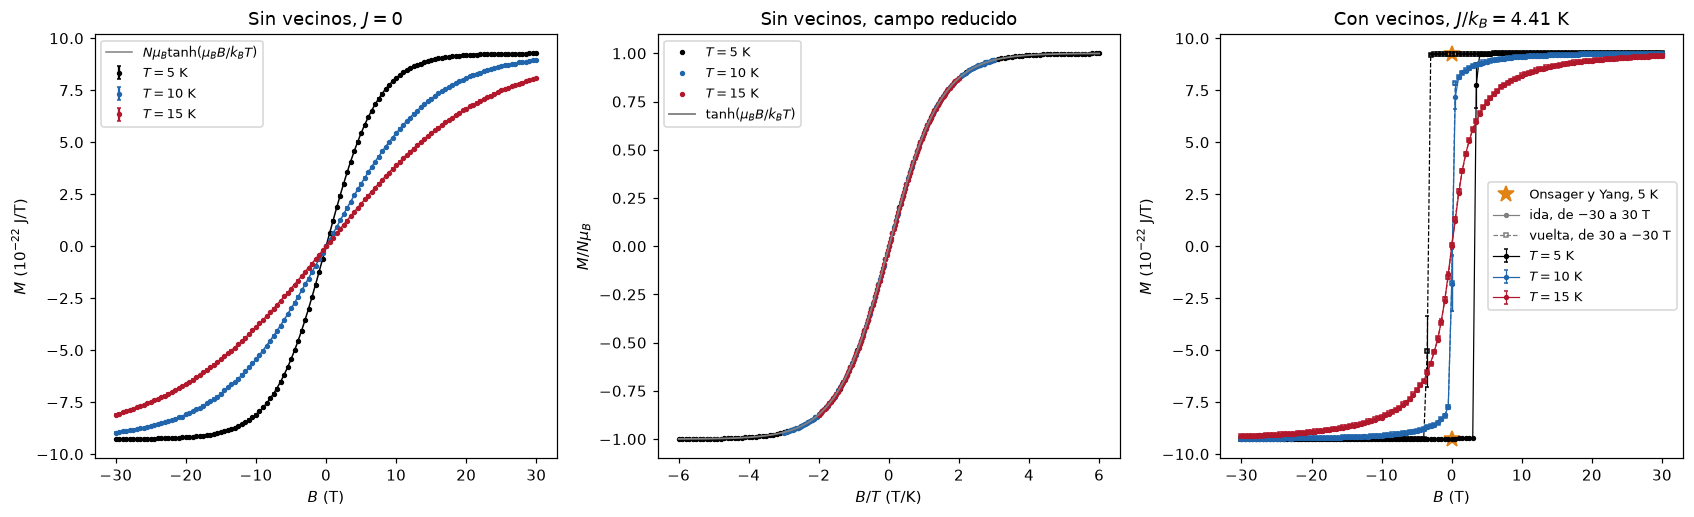

In [7]:
colores = {5: "black", 10: "#2166ac", 15: "#b2182b"}
escala = 1e-22
B_fino = np.linspace(-30, 30, 601)

fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.8))
for T in temperaturas:
    tabla = datos[(datos["J/k_B"] == 0) & (datos["T"] == T)]
    ax[0].errorbar(tabla["B"], tabla["M"]/escala, yerr=tabla["error"]/escala, fmt="o", markersize=2.5, capsize=1.5,
                   color=colores[T], label=f"$T={T}$ K")
    curva = []
    for B in B_fino:
        curva.append(N*mu_B*math.tanh(mu_B*B/(k_B*T))/escala)
    ax[0].plot(B_fino, curva, color=colores[T], linewidth=1.0)

    ax[1].plot(tabla["B"]/T, tabla["M"]/(N*mu_B), "o", markersize=2.5, color=colores[T], label=f"$T={T}$ K")

    tabla = datos[(datos["J/k_B"] > 0) & (datos["T"] == T) & (datos["recorrido"] == "ida")]
    ax[2].errorbar(tabla["B"], tabla["M"]/escala, yerr=tabla["error"]/escala, fmt="o-", markersize=2.5,
                   linewidth=0.8, capsize=1.5, color=colores[T], label=f"$T={T}$ K")
    tabla = datos[(datos["J/k_B"] > 0) & (datos["T"] == T) & (datos["recorrido"] == "vuelta")]
    ax[2].errorbar(tabla["B"], tabla["M"]/escala, yerr=tabla["error"]/escala, fmt="s--", markersize=2.5,
                   linewidth=0.8, capsize=1.5, color=colores[T], mfc="none")

reducido = np.linspace(-6, 6, 601)
curva = []
for y in reducido:
    curva.append(math.tanh(mu_B*y/k_B))
ax[1].plot(reducido, curva, color="gray", linewidth=1.2, label=r"$\tanh(\mu_BB/k_BT)$")

m_exacta = (1 - math.sinh(2*J_vecinos/(k_B*5))**-4)**(1/8)
ax[2].plot([0, 0], [m_exacta*N*mu_B/escala, -m_exacta*N*mu_B/escala], "*", color="#e08214", markersize=11,
           label="Onsager y Yang, 5 K")

ax[0].plot([], [], color="gray", linewidth=1.0, label=r"$N\mu_B\tanh(\mu_BB/k_BT)$")
ax[0].set_xlabel("$B$ (T)")
ax[0].set_ylabel(r"$M$ ($10^{-22}$ J/T)")
ax[0].set_title("Sin vecinos, $J=0$")
ax[0].legend(fontsize=8.5)
ax[1].set_xlabel("$B/T$ (T/K)")
ax[1].set_ylabel(r"$M/N\mu_B$")
ax[1].set_title("Sin vecinos, campo reducido")
ax[1].legend(fontsize=8.5)
ax[2].plot([], [], "o-", color="gray", markersize=2.5, linewidth=0.8, label="ida, de $-30$ a $30$ T")
ax[2].plot([], [], "s--", color="gray", mfc="none", markersize=2.5, linewidth=0.8, label="vuelta, de $30$ a $-30$ T")
ax[2].set_xlabel("$B$ (T)")
ax[2].set_ylabel(r"$M$ ($10^{-22}$ J/T)")
ax[2].set_title(f"Con vecinos, $J/k_B={J_vecinos/k_B:.2f}$ K")
ax[2].legend(fontsize=8.5, loc="center right")
fig.tight_layout()
plt.show()

Sin vecinos, los puntos siguen $N\mu_B\tanh(\mu_BB/k_BT)$ en las tres temperaturas: 333 de los 363 quedan a menos de dos
errores de la curva, y la diferencia máxima es el 0,5 % de $N\mu_B$. Contra $B/T$ los tres conjuntos caen sobre la misma
curva, como anticipa el paso 3. En 5 K la magnetización satura antes de 30 T; en 15 K llega al 87 % de $N\mu_B$, porque
$k_BT/\mu_B=22{,}3$ T.

Con vecinos, la magnetización con el campo apagado coincide con la de Onsager y Yang. En 5 K vale $-0{,}9978\pm0{,}0002$
en la ida y $+0{,}9980\pm0{,}0001$ en la vuelta, frente a $(63/64)^{1/8}=0{,}9980$, y la red invierte su magnetización
solo cuando el campo contrario llega a 3,5 T, que es el ciclo de histéresis de un ferromagneto. Ese campo de inversión
depende del número de barridos en cada campo, porque la red con la magnetización contraria al campo es metaestable, y no tiene expresión exacta.
En 15 K no hay histéresis y $M(0)$ es cero dentro del error, pero la respuesta al campo es mucho mayor que sin vecinos:
en 1 T la magnetización es el 27 a 29 % de $N\mu_B$, frente al 4,5 % con $J=0$. En 10 K, la temperatura crítica,
$M(0)=-0{,}19\pm0{,}14$ en los dos recorridos, compatible con cero; en una red de $10\times10$ las fluctuaciones en $T_c$
son grandes, y con 1 T la magnetización ya llega al 88 %. Con vecinos, $M$ deja de depender solo de $B/T$.

---

## Referencias

- Enunciado: [`Laboratorios/Lab_8_MCMC.ipynb`](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Laboratorios/Lab_8_MCMC.ipynb).
- Material del curso: [`Sesiones/MC/1_Monte_Carlo_MC_integration.ipynb`](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/MC/1_Monte_Carlo_MC_integration.ipynb), para la rutina
  `monte_carlo_integration`, y [`Sesiones/MC/2_Monte_Carlo_Marckov_chain_MCMC.ipynb`](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/MC/2_Monte_Carlo_Marckov_chain_MCMC.ipynb),
  para el algoritmo de Metropolis y el modelo de Ising 2D sin interacción.
- F. Reif, *Fundamentals of Statistical and Thermal Physics*, McGraw-Hill (1965), la bibliografía de la sesión.
- E. Ising, Beitrag zur Theorie des Ferromagnetismus, *Z. Phys.* **31**, 253 (1925).
- R. Peierls, On Ising's model of ferromagnetism, *Proc. Cambridge Philos. Soc.* **32**, 477 (1936).
- L. Onsager, Crystal Statistics. I. A Two-Dimensional Model with an Order-Disorder Transition, *Phys. Rev.*
  **65**, 117 (1944).
- C. N. Yang, The Spontaneous Magnetization of a Two-Dimensional Ising Model, *Phys. Rev.* **85**, 808 (1952).
- A. M. Ferrenberg, J. Xu y D. P. Landau, Pushing the limits of Monte Carlo simulations for the three-dimensional
  Ising model, *Phys. Rev. E* **97**, 043301 (2018).
- Constantes: [CODATA 2022, NIST](https://physics.nist.gov/cuu/Constants/), para $\mu_B$ y $k_B$.